# Machine Learning Assignment 2
## Online Shoppers Purchasing Intention Prediction Using Classification Models

### 1. Dataset Description

The **Online Shoppers Purchasing Intention Dataset** is obtained from the UCI Machine Learning Repository (Dataset ID: 468).

The dataset contains information about visitors browsing an online shopping website. It includes details such as the number of pages visited, time spent on different pages, bounce rates, exit rates, visitor types, and other browsing-related information.

The dataset contains **12,330 records, 17 input features, and 1 target variable**.

The target variable is **Revenue**, which indicates whether an online shopping session resulted in a purchase.

- **Revenue = True (1):** The visitor completed a purchase.
- **Revenue = False (0):** The visitor did not complete a purchase.

The dataset contains 10,422 sessions without purchases and 1,908 sessions with purchases.

Since the target variable has only two possible outcomes, this is a **Binary Classification Problem**.

### 2. Objective of the Project

The main objective of this project is to **predict whether an online shopping visitor will make a purchase based on their browsing behaviour** using Machine Learning classification algorithms.

We will implement five classification models on the same dataset and compare their performance using different evaluation metrics.

The project also aims to identify which classification algorithm performs best for predicting customer purchasing intentions.

In [30]:
# installing ucimlrepo
!pip install -q ucimlrepo


In [31]:
# Libraries used for data preparation, training, evaluation, and saving results
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             ConfusionMatrixDisplay)


**Step 1: Data Understanding**

Load the dataset and examine its structure, features, target variable, and class distribution.

In [32]:

from ucimlrepo import fetch_ucirepo

# Load Online Shoppers Purchasing Intention Dataset
dataset = fetch_ucirepo(id=468)

# Features and target
X = dataset.data.features
y = dataset.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
print(y.value_counts())


Features shape: (12330, 17)
Target shape: (12330, 1)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


Revenue
False      10422
True        1908
Name: count, dtype: int64


**Step 2: Data Preprocessing**

Check for missing values and duplicate records.

In [33]:

# Check missing values in each feature
print("Missing values in features:")
print(X.isnull().sum())

Missing values in features:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
dtype: int64


In [34]:
# Check missing values in target
print("\nMissing values in target:")
print(y.isnull().sum())



Missing values in target:
Revenue    0
dtype: int64


In [35]:

# Check feature data types
print("\nFeature data types:")
print(X.dtypes)


Feature data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
dtype: object


In [36]:

# Combine features and target for duplicate checking

df = pd.concat([X, y], axis=1)

print("Total rows:", df.shape[0])
print("Duplicate rows:", df.duplicated().sum())

# We are checking duplicates, but do not delete them yet. Some online shopping sessions can legitimately have identical feature values.

Total rows: 12330
Duplicate rows: 125


Prepare the target column
Machine Learning models work with numerical target labels. We'll convert:
- False → 0 (No Purchase)
- True →   1 (Purchase)

In [37]:


# Convert Revenue to numeric labels
y = y["Revenue"].astype(int)

print("Target values:")
print(y.value_counts())


Target values:
Revenue
0    10422
1     1908
Name: count, dtype: int64


**Step 3: Train-Test Split**

Divide the dataset into 80% training data and 20% testing data.

In [38]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training records: 9864
Testing records: 2466

Training target distribution:
Revenue
0    8338
1    1526
Name: count, dtype: int64

Testing target distribution:
Revenue
0    2084
1     382
Name: count, dtype: int64


**Data Preprocessing** - Convert categorical features into numerical representations, and apply feature scaling where required.

In [39]:
#To Identify categorical and numerical features

categorical_columns = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nNumber of categorical columns:",
      len(categorical_columns))

print("Number of numerical columns:",
      len(numerical_columns))


Categorical columns:
['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Number of categorical columns: 7
Number of numerical columns: 10


In [40]:
# Convert categories into numerical columns
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Scale numerical columns
numerical_transformer = StandardScaler()

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer,
         numerical_columns),
        ("cat", categorical_transformer,
         categorical_columns)
    ]
)

print("Preprocessing Configuration:")
print(preprocessor)

Preprocessing Configuration:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'BounceRates', 'ExitRates', 'PageValues',
                                  'SpecialDay']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Month', 'VisitorType', 'Weekend',
                                  'OperatingSystems', 'Browser', 'Region',
                                  'TrafficType'])])


** Step 4 & 5: Machine Learning Model Implementation and Model Evaluation **

Implement the following five classification algorithms:

*   Logistic Regression
*   Decision Tree Classifier
*   K-Nearest Neighbors (KNN)
*   Gaussian Naive Bayes
*   Support Vector Machine (SVM)

**Model Evaluation**

Evaluate each classification model using six performance metrics:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)




In [41]:
# Model 1 - Logistic Regression

# Create a Logistic Regression model pipeline
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict on test data
y_pred = logistic_model.predict(X_test)

# Calculate probability of purchase
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Logistic Regression Results :")
print("---------------------------")
print()
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))
print("Precision:", precision_score(y_test, y_pred,
                                    zero_division=0))
print("Recall:", recall_score(y_test, y_pred,
                              zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred,
                            zero_division=0))
print("MCC:", matthews_corrcoef(y_test, y_pred))


Logistic Regression Results :
---------------------------

Accuracy: 0.8807785888077859
AUC: 0.8827868275869
Precision: 0.7365591397849462
Recall: 0.3586387434554974
F1 Score: 0.4823943661971831
MCC: 0.45916112644753304


Decision Tree Evaluation Results : 
--------------------------------

Accuracy  : 0.8990
AUC       : 0.9172
Precision : 0.7111
Recall    : 0.5864
F1 Score  : 0.6428
MCC       : 0.5883



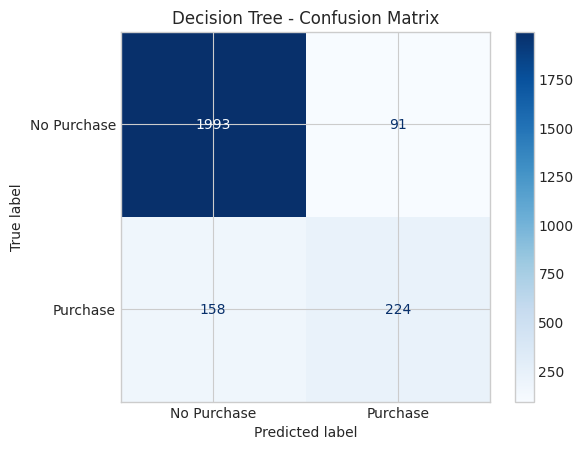

In [42]:
# Model 2 - Decision Tree Classifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)

# Predict test data
dt_pred = decision_tree_model.predict(X_test)

# Predict purchase probabilities
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Evaluate the model
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)
dt_precision = precision_score(
    y_test, dt_pred, zero_division=0
)
dt_recall = recall_score(
    y_test, dt_pred, zero_division=0
)
dt_f1 = f1_score(
    y_test, dt_pred, zero_division=0
)
dt_mcc = matthews_corrcoef(y_test, dt_pred)

print("Decision Tree Evaluation Results : ")
print("--------------------------------")
print()
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"AUC       : {dt_auc:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"MCC       : {dt_mcc:.4f}")

print()

#ConfusionMatrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()
print()




KNN Evaluation Results : 
----------------------

Accuracy  : 0.8767
AUC       : 0.7633
Precision : 0.6822
Recall    : 0.3822
F1 Score  : 0.4899
MCC       : 0.4493



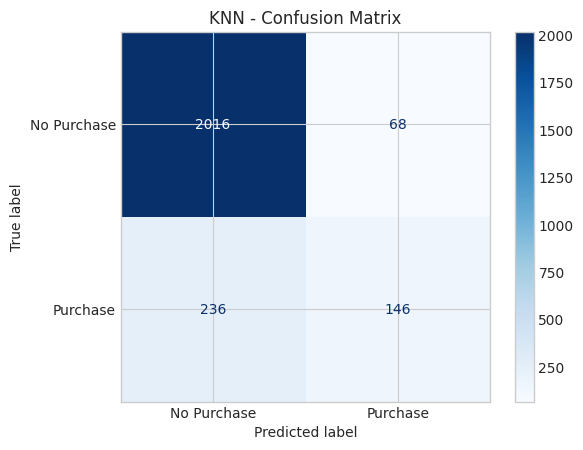

In [43]:
# Model 3 - K-Nearest Neighbors Classifier

# Create KNN model pipeline
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the KNN model
knn_model.fit(X_train, y_train)

# Predict test data
knn_pred = knn_model.predict(X_test)

# Predict purchase probabilities
knn_prob = knn_model.predict_proba(X_test)[:, 1]


#Evaluation the model

knn_accuracy = accuracy_score(y_test, knn_pred)

knn_auc = roc_auc_score(y_test, knn_prob)

knn_precision = precision_score(
    y_test, knn_pred, zero_division=0
)

knn_recall = recall_score(
    y_test, knn_pred, zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_pred, zero_division=0
)

knn_mcc = matthews_corrcoef(y_test, knn_pred)

print("KNN Evaluation Results : ")
print("----------------------")
print()
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"AUC       : {knn_auc:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")
print(f"MCC       : {knn_mcc:.4f}")
print()


# Confusion Matrix


ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.show()
print()


Gaussian Naive Bayes Results : 
----------------------------

Selected variance smoothing: 0.1
Training CV MCC: 0.4221

Accuracy : 0.7948
AUC      : 0.8070
Precision: 0.3980
Recall   : 0.6335
F1 Score : 0.4889
MCC      : 0.3844



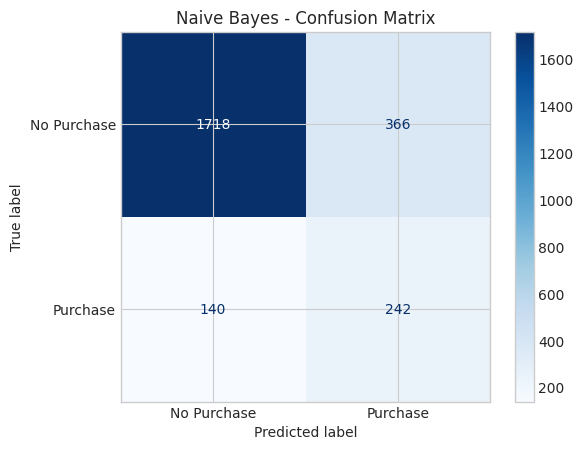

In [44]:
# Model 4: Gaussian Naive Bayes
# GaussianNB can become overconfident with one-hot encoded columns.
# Tune variance smoothing using only the training split (no test-set tuning).
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns)
    ],
    sparse_threshold=0
)

nb_pipeline = Pipeline([
    ("preprocessing", nb_preprocessor),
    ("classifier", GaussianNB())
])

# MCC is useful for this imbalanced purchase/non-purchase dataset.
nb_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid={"classifier__var_smoothing": [1e-9, 1e-6, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]},
    scoring="matthews_corrcoef",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=-1,
    refit=True
)
nb_search.fit(X_train, y_train)
nb_model = nb_search.best_estimator_

nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, list(nb_model.classes_).index(1)]
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_auc = roc_auc_score(y_test, nb_prob)
nb_precision = precision_score(y_test, nb_pred, zero_division=0)
nb_recall = recall_score(y_test, nb_pred, zero_division=0)
nb_f1 = f1_score(y_test, nb_pred, zero_division=0)
nb_mcc = matthews_corrcoef(y_test, nb_pred)

print("Gaussian Naive Bayes Results : ")
print("----------------------------")
print()
print("Selected variance smoothing:", nb_search.best_params_["classifier__var_smoothing"])
print("Training CV MCC:", round(nb_search.best_score_, 4))
print()
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"AUC      : {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1 Score : {nb_f1:.4f}")
print(f"MCC      : {nb_mcc:.4f}")
print()

ConfusionMatrixDisplay.from_predictions(y_test, nb_pred,
    display_labels=["No Purchase", "Purchase"], cmap="Blues")
plt.title("Naive Bayes - Confusion Matrix")
plt.show()


Support Vector Machine Evaluation Results : 
-----------------------------------------
Accuracy  : 0.8873
AUC       : 0.8824
Precision : 0.7047
Recall    : 0.4686
F1 Score  : 0.5629
MCC       : 0.5149



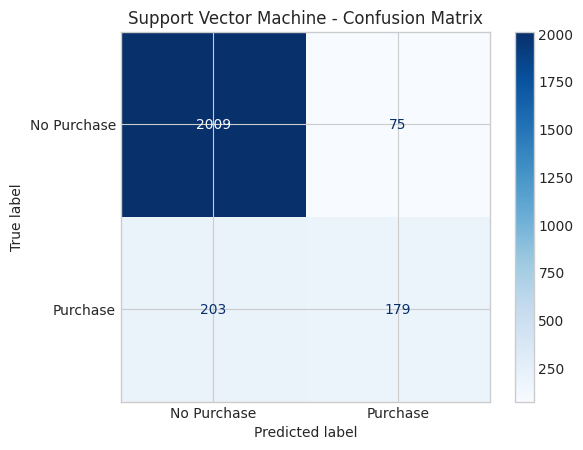

In [45]:

#Model 5 - Support Vector Machine Classifier


# Create SVM model pipeline
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

#Train SVM model
svm_model.fit(X_train, y_train)

#Predict test data
svm_pred = svm_model.predict(X_test)

# Predict purchase probabilities
svm_prob = svm_model.predict_proba(X_test)[:, 1]


#Evaluation the model

svm_accuracy = accuracy_score(y_test, svm_pred)

svm_auc = roc_auc_score(y_test, svm_prob)

svm_precision = precision_score(
    y_test, svm_pred, zero_division=0
)

svm_recall = recall_score(
    y_test, svm_pred, zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_pred, zero_division=0
)

svm_mcc = matthews_corrcoef(y_test, svm_pred)

print("Support Vector Machine Evaluation Results : ")
print("-----------------------------------------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"AUC       : {svm_auc:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")
print(f"MCC       : {svm_mcc:.4f}")
print()

#Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("Support Vector Machine - Confusion Matrix")
plt.show()

print()


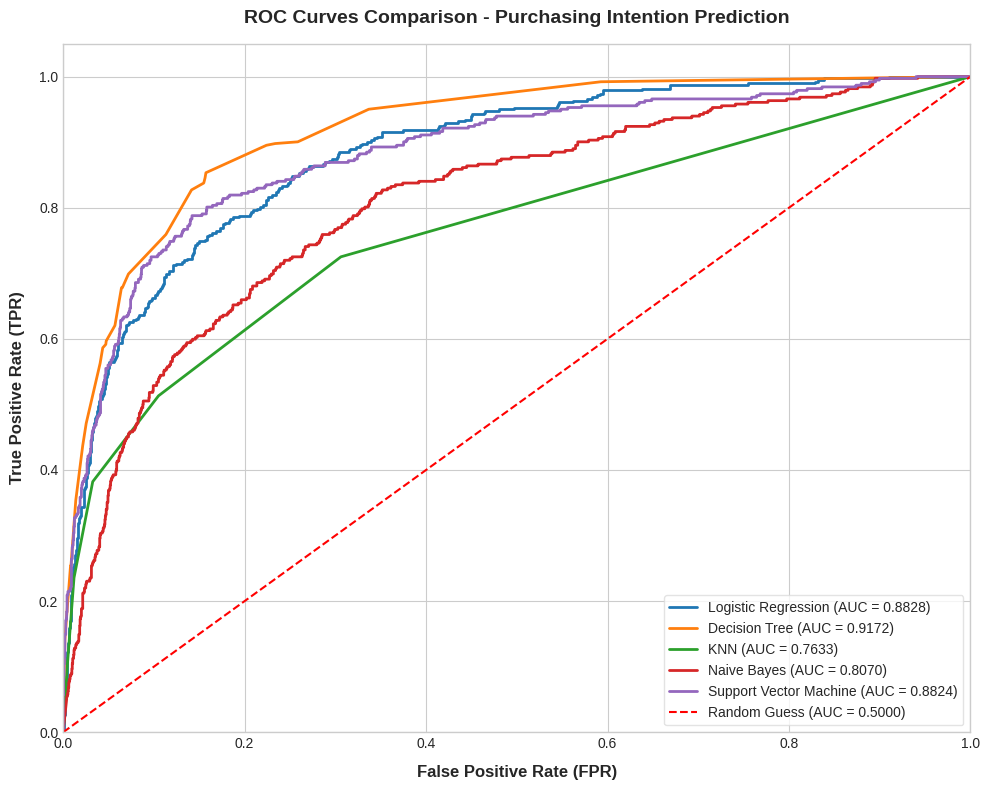

In [46]:
# Plot ROC Curves for all 5 classification models
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Configure the plotting style
plt.figure(figsize=(10, 8))
sns_style = "whitegrid"
plt.style.use('seaborn-v0_8-whitegrid') if 'seaborn-v0_8-whitegrid' in plt.style.available else plt.grid(True)

# Define models and their corresponding predicted probabilities from the test set
model_probs = {
    "Logistic Regression": y_prob,
    "Decision Tree": dt_prob,
    "KNN": knn_prob,
    "Naive Bayes": nb_prob,
    "Support Vector Machine": svm_prob
}

# Plot ROC curve for each model
for model_name, probs in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.4f})", lw=2)

# Plot the diagonal reference line for a random classifier
plt.plot([0, 1], [0, 1], color='red', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')

# Customize plot aesthetics
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('True Positive Rate (TPR)', fontsize=12, fontweight='bold', labelpad=10)
plt.title('ROC Curves Comparison - Purchasing Intention Prediction', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=10, frameon=True, facecolor='white', edgecolor='gainsboro')
plt.tight_layout()

# Display the plot
plt.show()

In [47]:

#Save all five trained models

import os
import joblib

# Create a folder to store trained models
os.makedirs("model", exist_ok=True)

models = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

# Save each trained pipeline
for name, model in models.items():
    joblib.dump(model, f"model/{name}.joblib")
    print(f"Saved: model/{name}.joblib")

print("\nAll five models saved successfully!")


Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/svm.joblib

All five models saved successfully!


In [48]:

#Save test dataset

import pandas as pd

test_data = X_test.copy()

# Add actual target values
test_data["Revenue"] = y_test

# Save CSV without index
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)

display(test_data.head())


Test dataset saved successfully!
Shape: (2466, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
4722,1,4.0,0,0.0,13,161.166667,0.024615,0.061538,0.000000,0.6,May,2,5,9,5,Returning_Visitor,False,0
6835,1,23.2,0,0.0,23,290.000000,0.000000,0.033333,0.000000,0.0,Jul,2,2,8,3,Returning_Visitor,False,0
5524,0,0.0,0,0.0,6,95.000000,0.028571,0.028571,86.336233,0.0,Oct,1,1,4,2,New_Visitor,False,1
663,0,0.0,0,0.0,2,17.000000,0.000000,0.100000,0.000000,0.0,Mar,1,1,8,3,Returning_Visitor,False,0
136,0,0.0,0,0.0,9,303.666667,0.005556,0.046296,0.000000,0.0,Feb,2,4,5,2,Returning_Visitor,False,0


**Step 6: Model Comparison**

Compare the results of all five models, analyze their performance, and identify the best-performing model for the selected dataset.


In [49]:

#Compare all five ML models

# Store predictions and probabilities
model_results = {
    "Logistic Regression": (y_pred, y_prob),
    "Decision Tree": (dt_pred, dt_prob),
    "KNN": (knn_pred, knn_prob),
    "Naive Bayes": (nb_pred, nb_prob),
    "Support Vector Machine": (svm_pred, svm_prob)
}

# Calculate all six metrics
results = []

for model_name, (pred, prob) in model_results.items():

    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, pred)
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

print("Final Model Comparison Table")
display(comparison_df.round(4))


Final Model Comparison Table


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592
1,Decision Tree,0.8990,0.9172,0.7111,0.5864,0.6428,0.5883
2,KNN,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493
3,Naive Bayes,0.7948,0.8070,0.3980,0.6335,0.4889,0.3844
4,Support Vector Machine,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149


Machine Learning Model Performance Comparison

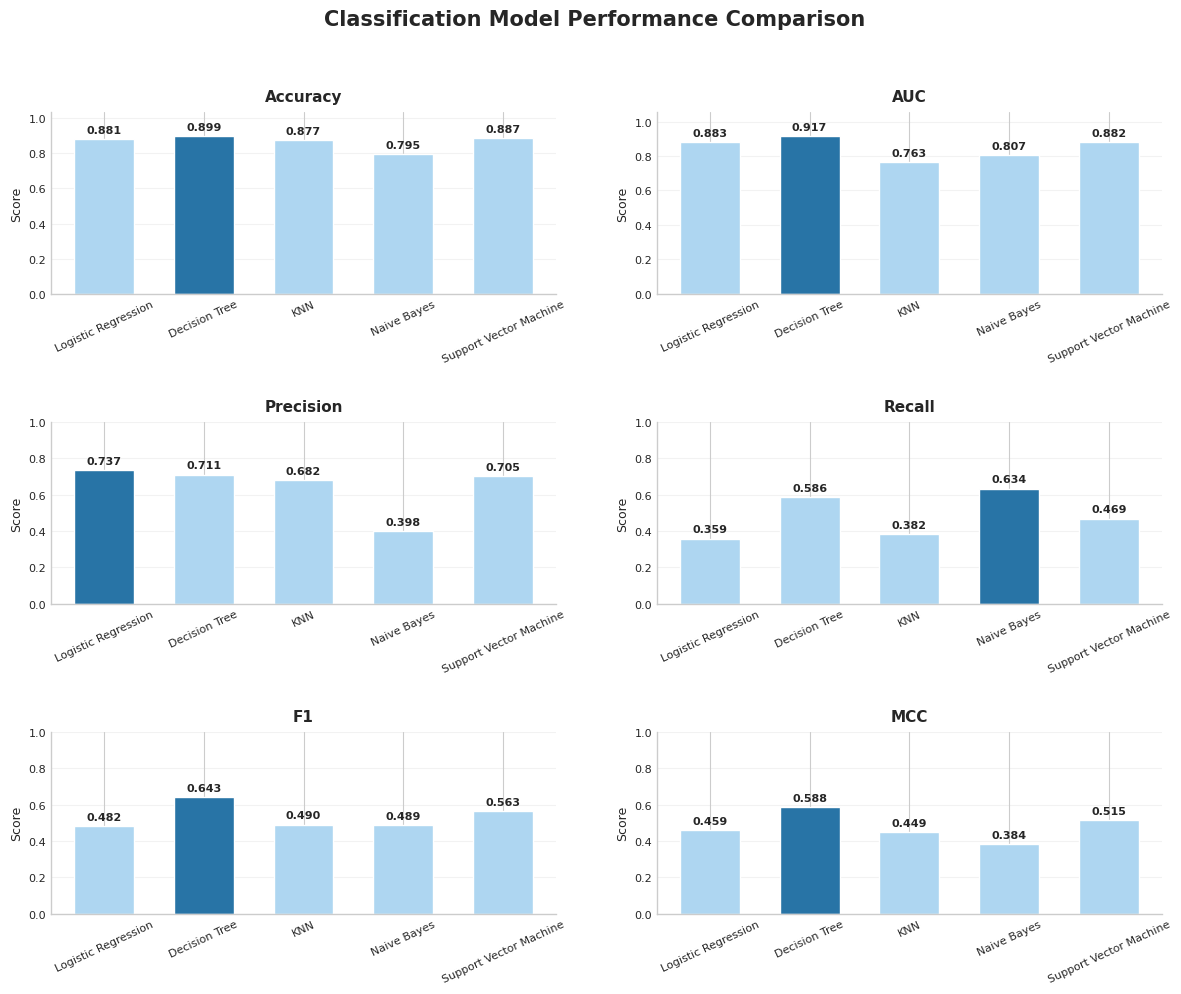

In [50]:

# Model Performance Comparison

import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1", "MCC"
]

sns.set_style("whitegrid")

# Create 3 rows and 2 columns
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

# Main title - displayed only once
fig.suptitle(
    "Classification Model Performance Comparison",
    fontsize=15,
    fontweight="bold",
    y=0.99
)

# Plot all evaluation metrics
for ax, metric in zip(axes.flat, metrics):

    values = comparison_df[metric]
    best_value = values.max()

    # Highlight best-performing model
    colors = [
        "#2874A6" if v == best_value else "#AED6F1"
        for v in values
    ]

    bars = ax.bar(
        comparison_df["ML Model Name"],
        values,
        color=colors,
        width=0.6
    )

    # Display scores above bars
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.3f}",
            (bar.get_x() + bar.get_width()/2, height),
            ha="center",
            va="bottom" if height >= 0 else "top",
            fontsize=8,
            fontweight="bold",
            xytext=(0, 3 if height >= 0 else -3),
            textcoords="offset points"
        )

    # Individual metric title
    ax.set_title(
        metric,
        fontsize=11,
        fontweight="bold",
        pad=8
    )

    ax.set_ylabel("Score", fontsize=9)
    ax.tick_params(axis="x", labelrotation=25, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

    # Handle negative MCC values
    ax.set_ylim(
        min(0, values.min() * 1.1),
        max(1, values.max() * 1.15)
    )

    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    sns.despine(ax=ax)

# Adjust spacing
fig.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.5, w_pad=3)

plt.show()


In [51]:
#Generate basic performance observations

for _, row in comparison_df.iterrows():

    print("\nModel:", row["ML Model Name"])

    print(
        f"Accuracy = {row['Accuracy']:.4f}, "
        f"AUC = {row['AUC']:.4f}"
    )

    print(
        f"Precision = {row['Precision']:.4f}, "
        f"Recall = {row['Recall']:.4f}"
    )

    print(
        f"F1 = {row['F1']:.4f}, "
        f"MCC = {row['MCC']:.4f}"
    )

    if row["Recall"] < 0.5:
        print(
            "Observation: The model misses more "
            "than half of actual purchase sessions."
        )
    else:
        print(
            "Observation: The model identifies "
            "at least half of actual purchase sessions."
        )

# Define the best model based on F1 Score
best_model = comparison_df.loc[comparison_df["F1"].idxmax()]

print("\nOverall Winner:",
      best_model["ML Model Name"])


Model: Logistic Regression
Accuracy = 0.8808, AUC = 0.8828
Precision = 0.7366, Recall = 0.3586
F1 = 0.4824, MCC = 0.4592
Observation: The model misses more than half of actual purchase sessions.

Model: Decision Tree
Accuracy = 0.8990, AUC = 0.9172
Precision = 0.7111, Recall = 0.5864
F1 = 0.6428, MCC = 0.5883
Observation: The model identifies at least half of actual purchase sessions.

Model: KNN
Accuracy = 0.8767, AUC = 0.7633
Precision = 0.6822, Recall = 0.3822
F1 = 0.4899, MCC = 0.4493
Observation: The model misses more than half of actual purchase sessions.

Model: Naive Bayes
Accuracy = 0.7948, AUC = 0.8070
Precision = 0.3980, Recall = 0.6335
F1 = 0.4889, MCC = 0.3844
Observation: The model identifies at least half of actual purchase sessions.

Model: Support Vector Machine
Accuracy = 0.8873, AUC = 0.8824
Precision = 0.7047, Recall = 0.4686
F1 = 0.5629, MCC = 0.5149
Observation: The model misses more than half of actual purchase sessions.

Overall Winner: Decision Tree


In [52]:

# Save final model comparison
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Final comparison:")

# Confirm the winning model
best_model = comparison_df.loc[
    comparison_df["F1"].idxmax()
]

print("\nBest Model   : ", best_model["ML Model Name"])
print("F1 Score     : ", round(best_model["F1"], 4))
print("Accuracy     : ", round(best_model["Accuracy"], 4))
print("AUC          : ", round(best_model["AUC"], 4))
print("MCC          : ", round(best_model["MCC"], 4))


Final comparison:

Best Model   :  Decision Tree
F1 Score     :  0.6428
Accuracy     :  0.899
AUC          :  0.9172
MCC          :  0.5883



**Step 7: Streamlit Application Development**

Develop an interactive Streamlit application where users can upload a test CSV file, select a trained classification model, and view its performance metrics and confusion matrix.


In [53]:
%%writefile app.py

import html as _html
import hashlib
import streamlit as st
import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, confusion_matrix, classification_report, roc_curve
)

st.set_page_config(page_title="Checkout Compass | Purchase Intent Analytics", page_icon="🧭", layout="wide")

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&display=swap');
:root{--ink:#162a43;--blue:#2854a1;--sky:#dceafb;--line:#dce5ef;--muted:#64758c;--paper:#f6f8fc}
html,body,.stApp,[data-testid="stAppViewContainer"]{font-family:'DM Sans',sans-serif!important;background:var(--paper)!important;color:var(--ink);color-scheme:light}
[data-testid="stHeader"]{background:transparent!important}
.block-container{max-width:1170px;padding-top:1.4rem;padding-bottom:4rem}
footer{visibility:hidden}
h1,h2,h3,p{font-family:'DM Sans',sans-serif}
[data-testid="stWidgetLabel"] p{color:#29476a!important;font-weight:700}
[data-testid="stCaptionContainer"]{color:#77879d!important}
/* Checkout Compass: purchase-intent analytics design */
[data-testid="stSidebar"]{background:#101f35!important;border-right:1px solid #29425f}
[data-testid="stSidebar"] [data-testid="stSidebarContent"]{background:#101f35!important}
[data-testid="stSidebar"] p,[data-testid="stSidebar"] a,[data-testid="stSidebar"] span{color:#dce9f8}
[data-testid="stSidebar"] a{text-decoration:none!important}
[data-testid="stSidebar"] a:hover{color:#8fd4ff!important}
.sidebrand{padding:12px 4px 20px;border-bottom:1px solid #29425f;margin-bottom:18px}
.sidebrand .mark{display:inline-flex;align-items:center;justify-content:center;width:43px;height:43px;background:#1b4774;border:1px solid #386d9d;border-radius:13px;font-size:24px;margin-bottom:12px}
.sidebrand strong{display:block;color:#fff;font-size:1.2rem;font-weight:800;letter-spacing:-.035em}
.sidebrand small{display:block;color:#a9c4e3;font-size:.76rem;margin-top:5px}
.sidelabel{font-size:.7rem;font-weight:800;letter-spacing:.15em;color:#8daed0;margin:17px 0 10px}
.sidelink{display:block;padding:10px 13px;margin:4px 0;background:#172c47;border:1px solid #294563;border-radius:10px;color:#e5f1ff!important;font-size:.85rem;font-weight:650}
.sidefoot{margin-top:25px;padding:15px;background:#19324d;border:1px solid #2d506e;border-radius:12px;color:#c9e2ff;font-size:.8rem;line-height:1.65}
.hero{position:relative;overflow:hidden;background:linear-gradient(112deg,#10233c 0%,#183f68 58%,#176d98 100%);border-radius:20px;padding:34px 38px;margin:3px 0 20px;box-shadow:0 12px 28px rgba(18,39,67,.12);border-left:5px solid #5ec3db}
.hero:after{content:'';position:absolute;width:270px;height:270px;border:45px solid rgba(255,255,255,.045);border-radius:50%;right:-125px;top:-150px;pointer-events:none}
.hero table,.hero tr,.hero td{border:0!important;background:transparent!important}
.hero table{width:100%;border-collapse:collapse}.hero td{vertical-align:middle;padding:0!important}
.hero .kick{color:#9cddf6;font-size:.74rem;font-weight:800;letter-spacing:.15em}
.hero h1{color:#fff!important;font-size:clamp(1.8rem,3vw,2.55rem);font-weight:800;letter-spacing:-.035em;line-height:1.2;margin:10px 0 12px}
.hero p{color:#d7e9f7;font-size:.96rem;line-height:1.6;max-width:670px;margin:0}
.hero .tag{display:inline-block;background:rgba(255,255,255,.10);border:1px solid rgba(255,255,255,.18);color:#f3faff;font-size:.72rem;font-weight:700;padding:6px 12px;border-radius:100px;margin:18px 7px 0 0}
.hero .cart{width:85px;height:85px;line-height:85px;text-align:center;font-size:2.5rem;border-radius:20px;background:rgba(255,255,255,.12);border:1px solid rgba(255,255,255,.2)}
.overview{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:13px;margin:18px 0 28px}
.overview .item{background:#fff;border:1px solid var(--line);border-top:3px solid #48a5c8;border-radius:13px;padding:17px 20px;box-shadow:0 4px 13px rgba(30,59,91,.035)}
.overview .label{font-size:.7rem;font-weight:800;letter-spacing:.12em;text-transform:uppercase;color:#6d829a}
.overview .value{font-size:1.65rem;font-weight:800;color:#1e4267;margin-top:6px}
.overview .detail{font-size:.75rem;color:#73879d;margin-top:4px}
.section-heading{font-family:'DM Sans',sans-serif!important;font-size:1.26rem!important;font-weight:800!important;letter-spacing:-.025em!important;color:#244b79!important;margin:30px 0 9px!important}
.sub{color:var(--muted);font-size:.9rem;line-height:1.55;margin:0 0 15px}
.workflow{background:#edf6fc;border:1px solid #cce3f1;border-radius:12px;padding:12px 16px;color:#355d7c;font-size:.83rem;margin:6px 0 18px}
.workflow b{color:#1d547b}
/* Keep Streamlit's working uploader, but do not show the unstyleable native black chip. */
[data-testid="stFileUploader"] section{background:#f1f7ff!important;border:1px solid #bad1e8!important;border-radius:13px!important;box-shadow:none!important}
[data-testid="stFileUploader"] section button{background:#fff!important;border:1px solid #b8cde4!important;color:#254a73!important;border-radius:9px!important}
[data-testid="stFileUploaderFile"]{background:#fff!important;border:1px solid #bad1e8!important;border-radius:10px!important}
[data-testid="stFileUploaderFile"] *{color:#254a73!important;-webkit-text-fill-color:#254a73!important}
.chips{margin:9px 0 14px}.chip{display:inline-block;background:#eaf3fc;border:1px solid #cfe0ef;color:#315c84;font-size:.77rem;font-weight:750;padding:8px 13px;border-radius:9px;margin:0 7px 7px 0}
.bal{width:100%;border-collapse:collapse;margin:11px 0 15px;table-layout:fixed}.bal td{padding:11px 12px!important;font-size:.79rem;font-weight:750;color:#fff;white-space:nowrap;overflow:hidden;border:0!important}
.preview-inline-label{font-family:'DM Sans',sans-serif;color:#285487;font-size:.91rem;font-weight:750;white-space:nowrap}
[data-testid="stNumberInput"] [data-baseweb="input"],[data-testid="stNumberInput"] [data-baseweb="base-input"]{background:#dceafb!important;border:1px solid #b9d2ee!important;border-radius:9px!important;box-shadow:none!important;outline:none!important}
[data-testid="stNumberInput"] input{background:#dceafb!important;color:#285487!important;-webkit-text-fill-color:#285487!important;font-family:'DM Sans',sans-serif!important;font-weight:700!important}
[data-testid="stNumberInput"] button{background:#dceafb!important;color:#285487!important;border-color:#b9d2ee!important;box-shadow:none!important}
[data-testid="stNumberInput"] button:hover{background:#c5def9!important}
[data-testid="stNumberInput"] button svg{color:#285487!important}
[data-testid="stNumberInput"] [data-baseweb="input"]:focus-within{border-color:#78a8d9!important;box-shadow:none!important}
.preview-caption{color:#4c6686;font-size:.84rem;font-weight:700;margin:15px 0 10px}
/* Raw dataset: plain text only. Never relabel True/False or reorder columns. */
.tw{width:100%;max-height:440px;overflow:auto;background:#fff;border:1px solid #d5e0ec;border-radius:12px;box-shadow:0 4px 14px rgba(30,62,95,.05)}
.tw table.dt{width:max-content;min-width:100%;border-collapse:collapse;font-family:'DM Sans',sans-serif;font-size:12.5px}
.tw table.dt thead th{background:#f5f8fc!important;color:#285487!important;font-size:12px!important;font-weight:700!important;padding:12px 15px!important;text-align:left;white-space:nowrap;border:0!important;border-bottom:1px solid #dce5ee!important}
.tw table.dt tbody td{background:#fff!important;color:#334155!important;font-family:'DM Sans',sans-serif!important;font-size:12.5px!important;font-weight:400!important;padding:11px 15px!important;white-space:nowrap;border:0!important;border-bottom:1px solid #edf1f5!important}
.note{color:#6b7e95;font-size:.82rem;margin:11px 0 0}
[data-testid="stForm"]{background:#fff;border:1px solid var(--line);border-radius:16px;padding:20px 23px 18px;box-shadow:0 5px 16px rgba(20,36,61,.04)}
[data-testid="stSelectbox"] [data-baseweb="select"],[data-testid="stSelectbox"] [data-baseweb="select"]>div,[data-testid="stSelectbox"] [role="combobox"],[data-testid="stSelectbox"] [data-baseweb="select"]>div>div{background:#e7f2ff!important;color:#25496c!important;border-color:#bdd4eb!important}
[data-testid="stSelectbox"] [data-baseweb="select"] svg{color:#25496c!important}
[data-testid="stSelectbox"] [role="combobox"]{border:1px solid #bdd4eb!important;border-radius:10px!important;box-shadow:none!important}
[data-baseweb="popover"],[data-baseweb="menu"],[data-baseweb="popover"] [role="listbox"],[data-testid="stSelectboxVirtualDropdown"],[data-baseweb="menu"] li,[data-baseweb="menu"] [role="option"]{background:#eaf4ff!important;color:#25496c!important}
[data-baseweb="menu"] li:hover,[data-baseweb="menu"] [aria-selected="true"]{background:#cfe6ff!important}
/* Active model dropdown: consistent light-blue menu and legible options.
   BaseWeb mounts the open menu in a portal outside stSelectbox. */
[data-testid="stSelectbox"] [data-baseweb="select"] > div,
[data-testid="stSelectbox"] [role="combobox"],
[data-testid="stSelectbox"] [data-baseweb="select"] [data-baseweb="select-arrow"] {
  background-color:#e7f2ff!important;color:#25496c!important;
  border-color:#bdd4eb!important;box-shadow:none!important;
}
[data-testid="stSelectbox"] [role="combobox"]:focus-within {
  outline:2px solid #8ab9e8!important;outline-offset:0!important;
  border-color:#8ab9e8!important;box-shadow:none!important;
}
[data-baseweb="popover"] [data-baseweb="menu"],
[data-baseweb="popover"] [role="listbox"],
[data-testid="stSelectboxVirtualDropdown"],
[data-testid="stSelectboxVirtualDropdown"] [role="listbox"],
[data-testid="stVirtualDropdown"] [role="listbox"] {
  background:#eaf4ff!important;color:#25496c!important;
  border:1px solid #bdd4eb!important;border-radius:10px!important;
}
[data-baseweb="popover"] [role="option"],
[data-baseweb="popover"] [role="option"] *,
[data-baseweb="popover"] [data-baseweb="menu"] li,
[data-baseweb="popover"] [data-baseweb="menu"] li *,
[data-testid="stSelectboxVirtualDropdown"] [role="option"],
[data-testid="stSelectboxVirtualDropdown"] [role="option"] *,
[data-testid="stVirtualDropdown"] [role="option"],
[data-testid="stVirtualDropdown"] [role="option"] * {
  background-color:transparent!important;
  color:#25496c!important;-webkit-text-fill-color:#25496c!important;
  font-family:'DM Sans',sans-serif!important;font-weight:600!important;
}
[data-baseweb="popover"] [role="option"]:hover,
[data-baseweb="popover"] [role="option"][aria-selected="true"],
[data-baseweb="popover"] [data-baseweb="menu"] li:hover,
[data-testid="stSelectboxVirtualDropdown"] [role="option"]:hover,
[data-testid="stSelectboxVirtualDropdown"] [aria-selected="true"] {
  background:#cfe6ff!important;
}
[data-testid="stFormSubmitButton"] button{background:#2563eb!important;color:#fff!important;border:0!important;border-radius:10px!important;font-weight:800!important;padding:.65rem 1.5rem!important;min-height:44px}
[data-testid="stFormSubmitButton"] button:hover{background:#1d4ed8!important}
.verdict{background:#eaf2ff;border:1px solid #cfe0ff;color:#26476d;border-radius:14px;padding:17px 20px;margin:10px 0 20px;font-size:.94rem;line-height:1.65}.verdict b{color:#164bb3}
.metric-grid{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:14px;margin:8px 0 22px}
.mc{background:#fff;border:1px solid var(--line);border-radius:15px;padding:19px 17px;box-shadow:0 5px 18px rgba(20,36,61,.045);min-width:0}
.mc .nm{font-size:.78rem;color:#61728a;font-weight:800}.mc .vl{font-size:clamp(1.4rem,2.6vw,2rem);font-weight:800;color:var(--ink);line-height:1.3;margin:7px 0 12px}.mc .bar{height:7px;border-radius:8px;background:#edf2f7;overflow:hidden}.mc .bar i{display:block;height:100%;border-radius:8px}.mc .ht{font-size:.77rem;color:#718096;margin-top:11px;line-height:1.4}
.cmw{max-width:620px;margin:18px auto 0;padding:22px;background:#fff;border:1px solid #dbe6f2;border-radius:18px;box-shadow:0 7px 22px rgba(23,53,89,.06)}
.matrix-axis{text-align:center;font-size:.86rem;font-weight:750;color:#496682;margin-bottom:15px}.matrix-grid{display:grid;grid-template-columns:minmax(105px,1fr) minmax(0,1.3fr) minmax(0,1.3fr);gap:12px;align-items:stretch}.matrix-label{display:flex;align-items:center;justify-content:center;text-align:center;background:#edf3fb;color:#294967;font-size:.82rem;font-weight:750;border-radius:11px;padding:12px 8px;min-width:0}.matrix-label.row-label{justify-content:flex-start;text-align:left;padding-left:14px}.matrix-cell{min-width:0;min-height:125px;display:flex;flex-direction:column;justify-content:center;align-items:center;text-align:center;border-radius:13px;padding:18px 8px;border:1px solid transparent}.matrix-cell.tn{background:#dff4ee;border-color:#b6e2d3}.matrix-cell.tp{background:#e0ecff;border-color:#b6cdf4}.matrix-cell.fp{background:#fff0dc;border-color:#f0d4aa}.matrix-cell.fn{background:#fae8ee;border-color:#eec6d4}.matrix-cell .n{font-size:1.9rem;font-weight:800;line-height:1.2;color:#193955}.matrix-cell .l{font-size:.79rem;font-weight:700;color:#294967;margin-top:9px}.matrix-foot{text-align:center;color:#64748b;font-size:.75rem;margin-top:15px}
[data-testid="stExpander"]{background:#fff;border:1px solid var(--line);border-radius:12px}[data-testid="stExpander"] details>summary{background:#e9f2ff!important;color:#28518a!important}[data-testid="stExpander"] details>summary *{color:#28518a!important}[data-testid="stExpander"] .katex,[data-testid="stExpander"] .katex *{color:#28518a!important}[data-testid="stExpander"] .katex-display{margin:.5em 0!important}
@media(max-width:700px){.block-container{padding:1rem .8rem 3rem}.hero{padding:25px 20px}.hero .cart{display:none!important}.hero td:last-child{display:none}.overview{grid-template-columns:1fr}.metric-grid{grid-template-columns:repeat(2,minmax(0,1fr));gap:8px}.mc{padding:12px 10px}.mc .nm{font-size:.67rem}.mc .ht{font-size:.7rem}.cmw{padding:12px}.matrix-grid{gap:6px;grid-template-columns:minmax(75px,1fr) repeat(2,minmax(0,1.3fr))}.matrix-cell{min-height:100px;padding:10px 4px}.matrix-cell .n{font-size:1.35rem}}


/* Model comparison: restrained typography and an easy-to-scan table. */
.compare-scroll{overflow-x:auto;border:1px solid #dce5ef;border-radius:12px;background:#fff;margin:12px 0 8px}
.compare-table{width:100%;min-width:760px;border-collapse:collapse;font-family:'DM Sans',sans-serif;font-size:13px;color:#334155;font-variant-numeric:tabular-nums}
.compare-table th{background:#f2f6fb;color:#285487;font-weight:700;text-align:right;padding:14px 12px;border-bottom:1px solid #dce5ef;white-space:nowrap}
.compare-table th:first-child,.compare-table td:first-child{text-align:left;padding-left:18px;min-width:175px}
.compare-table td{background:#fff;text-align:right;padding:13px 12px;border-bottom:1px solid #edf1f5;white-space:nowrap;font-weight:500}
.compare-table tbody tr:last-child td{border-bottom:0}
.compare-table tbody tr:hover td{background:#f8fbff}
.compare-table td.model-name{color:#253d5a;font-weight:650}
.compare-table td.best-score{color:#205f91;font-weight:800;background:#eef6fd}
.comparison-chart-title{font-size:1.12rem!important;margin-top:26px!important}

/* Deliberate, restrained table and chart styling */
[data-testid="stTabs"] [data-baseweb="tab-list"]{gap:8px;flex-wrap:wrap}
[data-testid="stTabs"] [data-baseweb="tab"]{background:#edf4fb!important;border-radius:10px 10px 0 0;color:#345875!important;font-weight:700!important}
[data-testid="stTabs"] [aria-selected="true"]{background:#dbeeff!important;color:#173e6a!important}
[data-testid="stDataFrame"]{border:1px solid #d8e4f0;border-radius:12px;overflow:hidden}
[data-testid="stDownloadButton"] button,[data-testid="stButton"] button{border-radius:10px!important;font-weight:700!important}
[data-testid="stButton"] button[kind="primary"]{background:#2563eb!important;color:white!important}
.insight-panel{background:#fff;border:1px solid #d8e5f0;border-left:4px solid #19a3aa;border-radius:12px;padding:17px 20px;margin:14px 0 24px;color:#34516e;line-height:1.6}
.insight-panel strong{color:#1e486c}
.data-note{background:#eef6fc;border:1px solid #d3e6f4;border-radius:12px;padding:14px 18px;margin:12px 0;color:#355b7a;font-size:.88rem}
/* Uploaded-file chip: light surface (see the rule near the uploader). */

/* Tabs: make labels and active indicator visible in light and dark browser themes. */
[data-testid="stTabs"] [data-baseweb="tab-list"] {
  display:flex!important; flex-wrap:wrap!important; gap:8px!important;
  background:#ffffff!important; border-bottom:1px solid #d4e2f0!important;
  padding:7px 4px!important; min-height:52px!important;
}
[data-testid="stTabs"] button[data-baseweb="tab"],
[data-testid="stTabs"] [role="tab"] {
  display:inline-flex!important; visibility:visible!important; opacity:1!important;
  min-height:39px!important; padding:9px 14px!important;
  background:#eaf2fc!important; border:1px solid #c6d9ed!important;
  border-radius:9px!important; color:#24496e!important;
  font-family:'DM Sans',sans-serif!important; font-size:.88rem!important;
  font-weight:700!important; -webkit-text-fill-color:#24496e!important;
}
[data-testid="stTabs"] button[data-baseweb="tab"] *,
[data-testid="stTabs"] [role="tab"] * {
  color:#24496e!important; -webkit-text-fill-color:#24496e!important;
  opacity:1!important; visibility:visible!important;
}
[data-testid="stTabs"] [role="tab"][aria-selected="true"] {
  background:#d4e9ff!important; border-color:#6b9bc9!important;
  box-shadow:inset 0 -3px 0 #2865a0!important;
}
[data-testid="stTabs"] [data-baseweb="tab-highlight"] {background:#2865a0!important;}
[data-testid="stTabs"] [data-baseweb="tab-border"] {background:#d4e2f0!important;}
[data-testid="stTabs"] [data-baseweb="tab-panel"] {background:#fff!important;color:#203b59!important;padding-top:15px!important;}


/* Dataset & methodology tables: light surfaces and consistent dashboard typography. */
.schema-table-wrap{background:#fff;border:1px solid #d5e2ef;border-radius:12px;overflow:hidden;margin:12px 0 18px;box-shadow:0 3px 12px rgba(24,57,89,.035)}
.schema-scroll{max-height:460px;overflow:auto}
.schema-table{width:100%;border-collapse:collapse;font-family:'DM Sans',sans-serif!important;font-size:13px;color:#334155;background:#fff}
.schema-table th{background:#edf4fc!important;color:#285487!important;text-align:left;font-size:13px;font-weight:750;padding:13px 16px;border-bottom:1px solid #d5e2ef;white-space:nowrap}
.schema-table td{background:#fff!important;color:#334155!important;padding:12px 16px;border-bottom:1px solid #e8eef5;line-height:1.4;overflow-wrap:anywhere}
.schema-table tr:last-child td{border-bottom:0}
.schema-table tbody tr:nth-child(even) td{background:#fafcff!important}
.schema-table td:last-child{text-align:left}
.schema-scroll .schema-table th{position:sticky;top:0;z-index:1}

/* Requested: light comparison action and readable evaluation report. */
[data-testid="stButton"] button[kind="secondary"] {
  background:#e6f2ff!important;color:#285487!important;
  -webkit-text-fill-color:#285487!important;
  border:1px solid #b9d2ee!important;
  font-family:'DM Sans',sans-serif!important;font-weight:700!important;
  box-shadow:none!important;
}
[data-testid="stButton"] button[kind="secondary"]:hover {background:#d2e8fc!important;border-color:#83b5e0!important;}
[data-testid="stButton"] button[kind="secondary"]:disabled {background:#edf3f9!important;color:#7b8ea5!important;opacity:1!important;}
.classification-table th:first-child,.classification-table td:first-child{text-align:left}
.classification-table th:not(:first-child),.classification-table td:not(:first-child){text-align:right;font-variant-numeric:tabular-nums}


/* Final UI refinement: match multiselect chips, arrow, and number input to the Checkout Compass blue. */
[data-testid="stMultiSelect"] [data-baseweb="select"] > div,
[data-testid="stMultiSelect"] [role="combobox"] {
  background:#eaf4ff!important;color:#25496c!important;
  border:1px solid #bdd4eb!important;border-radius:10px!important;
  box-shadow:none!important;
}
[data-testid="stMultiSelect"] [data-baseweb="tag"] {
  background:#d1e7fb!important;color:#24496e!important;
  border:1px solid #a9cde9!important;border-radius:7px!important;
}
[data-testid="stMultiSelect"] [data-baseweb="tag"] *,
[data-testid="stMultiSelect"] [data-baseweb="select"] svg,
[data-testid="stMultiSelect"] input {
  color:#24496e!important;-webkit-text-fill-color:#24496e!important;
  font-family:'DM Sans',sans-serif!important;
}
[data-testid="stMultiSelect"] [data-baseweb="tag"] svg {fill:#24496e!important;}
[data-testid="stSelectbox"] [data-baseweb="select"] [role="combobox"] > div,
[data-testid="stSelectbox"] [data-baseweb="select"] [role="combobox"] svg {
  background:#e7f2ff!important;color:#25496c!important;
}
[data-testid="stNumberInput"] [data-baseweb="input"],
[data-testid="stNumberInput"] [data-baseweb="base-input"],
[data-testid="stNumberInput"] [data-baseweb="input"] > div {
  border-color:#b9d2ee!important;outline:none!important;box-shadow:none!important;
}
[data-testid="stNumberInput"] [data-baseweb="input"]:focus-within {
  border-color:#78a8d9!important;box-shadow:none!important;
}
/* Select arrow area and every inner box of the model dropdown stay light. */
[data-testid="stSelectbox"] [data-baseweb="select"] div{background-color:#e7f2ff!important;color:#25496c!important}
[data-testid="stForm"]{overflow-x:hidden}
/* Light surfaces for any portal-hosted metric choices. */
[data-baseweb="popover"] [role="listbox"],
[data-baseweb="popover"] [role="option"] {
  color:#25496c!important;-webkit-text-fill-color:#25496c!important;
  font-family:'DM Sans',sans-serif!important;
}
/* Keep horizontal scrolling obvious, without changing original table values. */
.tw,.compare-scroll {scrollbar-color:#a8c5e3 #edf4fb;scrollbar-width:thin;}
.tw::-webkit-scrollbar,.compare-scroll::-webkit-scrollbar {height:9px;}
.tw::-webkit-scrollbar-thumb,.compare-scroll::-webkit-scrollbar-thumb {background:#a8c5e3;border-radius:9px;}
.tw::-webkit-scrollbar-track,.compare-scroll::-webkit-scrollbar-track {background:#edf4fb;}
/* ===== Rows-to-preview box: ONE thin line, also while typing (outer border only, no inner border/shadow/outline) ===== */
[data-testid="stNumberInput"] [data-baseweb="base-input"]{border:0!important;box-shadow:none!important;outline:0!important;background:transparent!important}
[data-testid="stNumberInput"] [data-baseweb="input"]{border:1px solid #b9d2ee!important;box-shadow:none!important;outline:0!important}
[data-testid="stNumberInput"] [data-baseweb="input"]:focus-within{border:1px solid #6fa3d8!important;box-shadow:none!important;outline:0!important}
[data-testid="stNumberInput"] input,[data-testid="stNumberInput"] input:focus,[data-testid="stNumberInput"] input:focus-visible,[data-testid="stNumberInput"] input:active{
  border:0!important;box-shadow:none!important;outline:0!important;caret-color:#285487}
[data-testid="stNumberInput"] button:focus,[data-testid="stNumberInput"] button:focus-visible,[data-testid="stNumberInput"] button:active{
  outline:0!important;box-shadow:none!important}

/* ===== File uploader: light before AND after a file is chosen (no black chip / black fill) ===== */
[data-testid="stFileUploader"],[data-testid="stFileUploader"]>div{background:transparent!important}
[data-testid="stFileUploader"] div,[data-testid="stFileUploader"] section,[data-testid="stFileUploader"] small,[data-testid="stFileUploader"] span,[data-testid="stFileUploader"] p{
  background-color:#f1f7ff!important;color:#254a73!important;-webkit-text-fill-color:#254a73!important}
[data-testid="stFileUploader"] section{border:1px solid #bad1e8!important;border-radius:13px!important}
[data-testid="stFileUploader"] [data-testid="stFileUploaderFile"],[data-testid="stFileUploader"] [data-testid="stFileUploaderFile"] div,[data-testid="stFileUploader"] [data-testid="stFileUploaderFileData"],[data-testid="stFileUploader"] [data-testid="stFileUploaderFileData"] div{
  background-color:#ffffff!important}
[data-testid="stFileUploader"] [data-testid="stFileUploaderFile"]{border:1px solid #bad1e8!important;border-radius:10px!important}
[data-testid="stFileUploader"] button{background-color:#ffffff!important;border:1px solid #b8cde4!important;color:#254a73!important;border-radius:9px!important}
[data-testid="stFileUploader"] svg{color:#2a5d9f!important}
[data-testid="stFileUploader"] button:hover{background-color:#e7f2ff!important}

/* ===== Compact column summary (no scrolling) ===== */
.schema-grid{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:8px;margin:8px 0 4px}
.sc{display:flex;align-items:center;gap:7px;background:#f8fbff;border:1px solid #dbe7f3;border-radius:10px;padding:7px 10px;min-width:0}
.sc .sn{flex:1 1 auto;min-width:0;font-size:12.5px;font-weight:700;color:#244b79;white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.sc .sd{flex:0 0 auto;font-size:11px;font-weight:700;color:#475f7a;background:#e4edf8;border-radius:6px;padding:2px 7px}
.sc .sm{flex:0 0 auto;font-size:11px;font-weight:700;border-radius:6px;padding:2px 7px;white-space:nowrap}
.sc .sm.ok{background:#dff3e8;color:#17744a}
.sc .sm.bad{background:#ffe6d1;color:#9a4b00}
@media(max-width:900px){.schema-grid{grid-template-columns:repeat(2,minmax(0,1fr))}}
@media(max-width:560px){.schema-grid{grid-template-columns:1fr}}


/* Final targeted refinements: preview choices, success notice, comparison and schema. */
[data-testid="stRadio"] [role="radiogroup"] {gap:9px!important;flex-wrap:wrap!important;}
[data-testid="stRadio"] [role="radiogroup"] label {background:#e8f2ff!important;border:1px solid #bdd4eb!important;border-radius:9px!important;padding:7px 12px!important;min-width:48px!important;justify-content:center!important;cursor:pointer!important;}
[data-testid="stRadio"] [role="radiogroup"] label p,
[data-testid="stRadio"] [role="radiogroup"] label span {font-family:'DM Sans',sans-serif!important;color:#244b79!important;-webkit-text-fill-color:#244b79!important;font-size:14px!important;font-weight:750!important;opacity:1!important;visibility:visible!important;}
[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) {background:#cde4fc!important;border-color:#609bcf!important;box-shadow:inset 0 0 0 1px #609bcf!important;}
[data-testid="stRadio"] [role="radiogroup"] label:has(input:checked) p {color:#174577!important;-webkit-text-fill-color:#174577!important;}
[data-testid="stRadio"] [role="radiogroup"] [data-baseweb="radio"] > div:first-child {background:#fff!important;border-color:#6e9ac6!important;}
.shop-success {display:flex;align-items:center;gap:11px;background:#e8f4ff;border:1px solid #b9d7ee;border-left:4px solid #3c8dbd;border-radius:11px;padding:13px 16px;margin:12px 0;color:#244b79;font:700 14px 'DM Sans',sans-serif;}
.shop-success .success-icon {display:inline-flex;align-items:center;justify-content:center;background:#cde9f8;color:#22678e;border-radius:50%;width:25px;height:25px;font-size:15px;flex-shrink:0;}
.compare-table td,.compare-table td.model-name {color:#28445f!important;-webkit-text-fill-color:#28445f!important;font-family:'DM Sans',sans-serif!important;font-size:13px!important;}
.compare-table td.best-score {color:#155d91!important;-webkit-text-fill-color:#155d91!important;background:#e8f3fd!important;font-weight:800!important;}
.compare-table th {color:#244b79!important;-webkit-text-fill-color:#244b79!important;}
.schema-grid {grid-template-columns:repeat(3,minmax(0,1fr));gap:6px!important;margin:5px 0 2px!important;}
.sc {padding:5px 8px!important;gap:5px!important;border-radius:8px!important;}
.sc .sn {font-size:11.5px!important;}
.sc .sd,.sc .sm {font-size:10px!important;padding:2px 5px!important;}
@media(max-width:900px){.schema-grid{grid-template-columns:repeat(2,minmax(0,1fr));}}
@media(max-width:560px){.schema-grid{grid-template-columns:1fr;}}

/* ===== Checkout Compass finishing touches ===== */
/* Rows-to-preview choices behave like clean pills: hide the native radio dot (it was black / red) */
[data-testid="stRadio"] label > *:not(:has(p)):not(input){display:none!important}
[data-testid="stRadio"] label{gap:0!important}
/* Dropdowns: every inner box light, no dark ring, no dark arrow block */
[data-baseweb="select"],[data-baseweb="select"] *{background-color:#e7f2ff!important;background-image:none!important;
  border-color:#bdd4eb!important;box-shadow:none!important;outline:0!important;color:#25496c!important}
/* Metric picker chips: blue instead of the default red */
[data-baseweb="tag"],[data-baseweb="tag"] *{background-color:#cfe3f7!important;border-color:#a9c9e8!important;color:#24496e!important}
/* Active tab: blue */
[data-testid="stTabs"] button[aria-selected="true"]{color:#174577!important}
[data-baseweb="tab-highlight"]{background-color:#2865a0!important}
[data-baseweb="tab-border"]{background-color:#d3e1ef!important}
/* Plain-English result sentence */
.verdict-note{background:#eef6ff;border:1px solid #cfe2f4;border-left:4px solid #2865a0;border-radius:12px;padding:13px 16px;
  color:#244b79;font-size:14px;line-height:1.6;margin:4px 0 16px}
.verdict-note b{color:#174577}
/* Column cards: full name on top, badges below, no truncation */
.sc{display:block!important;padding:7px 10px!important}
.sc .sn{display:block!important;white-space:normal!important;overflow:visible!important;text-overflow:clip!important;
  overflow-wrap:anywhere;line-height:1.25}
.sc .sb{display:flex;gap:5px;margin-top:5px;flex-wrap:wrap}

/* Sidebar brand details */
.sidebrand .branddesc{color:#c5daf2;font-size:.78rem;line-height:1.5;margin-top:11px}
.sidebrand .brandmeta{display:flex;flex-wrap:wrap;gap:6px;margin-top:11px}
.sidebrand .brandmeta span{background:#19324d;border:1px solid #2d506e;color:#c9e2ff;font-size:.68rem;font-weight:700;padding:3px 9px;border-radius:999px}

/* ===== Table text: dark navy, clear hierarchy, readable in any browser theme ===== */
table.classification-table th, table.compare-table th,
[data-testid="stMarkdownContainer"] table.classification-table th, [data-testid="stMarkdownContainer"] table.compare-table th{
  color:#1f4c80!important;-webkit-text-fill-color:#1f4c80!important;font-weight:800!important}
table.classification-table td, table.compare-table td,
table.classification-table td *, table.compare-table td *,
[data-testid="stMarkdownContainer"] table.classification-table td, [data-testid="stMarkdownContainer"] table.compare-table td{
  color:#1d3a5a!important;-webkit-text-fill-color:#1d3a5a!important;font-weight:600!important;opacity:1!important}
table.classification-table td:first-child, table.compare-table td.model-name,
[data-testid="stMarkdownContainer"] table.classification-table td:first-child, [data-testid="stMarkdownContainer"] table.compare-table td.model-name{
  color:#12304f!important;-webkit-text-fill-color:#12304f!important;font-weight:800!important}
table.classification-table td:last-child{color:#4a6785!important;-webkit-text-fill-color:#4a6785!important}
table.compare-table td.best-score,
[data-testid="stMarkdownContainer"] table.compare-table td.best-score{
  color:#0b5a9c!important;-webkit-text-fill-color:#0b5a9c!important;background:#e1f0fc!important;font-weight:800!important}

</style>
""", unsafe_allow_html=True)

BASE_DIR = Path(__file__).resolve().parent
MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors (KNN)": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine (SVM)": "model/svm.joblib",
}


@st.cache_resource(show_spinner=False, max_entries=5)
def load_model(model_path: str):
    return joblib.load(model_path)


def fmt_num(v) -> str:
    if pd.isna(v):
        return ""
    if float(v).is_integer():
        return f"{int(v):,}" if abs(v) >= 10000 else str(int(v))
    return f"{v:,.3f}".rstrip("0").rstrip(".")


def preview_table(df: pd.DataFrame, n: int) -> str:
    """Display CSV records as uploaded, without translating Revenue values."""
    view = df.head(n)
    head = "".join(f"<th>{_html.escape(str(c))}</th>" for c in view.columns)
    rows = []
    for _, row in view.iterrows():
        cells = []
        for value in row:
            shown = "" if pd.isna(value) else str(value)
            cells.append(f"<td>{_html.escape(shown)}</td>")
        rows.append(f"<tr>{''.join(cells)}</tr>")
    return f'<div class="tw"><table class="dt"><thead><tr>{head}</tr></thead><tbody>{"".join(rows)}</tbody></table></div>'


def balance_bar(pos: int, total: int) -> str:
    pos_pct = pos / total * 100
    neg_pct = 100 - pos_pct
    pos_w = max(pos_pct, 12)          # keep the small segment readable
    neg_w = 100 - pos_w
    return (f'<table class="bal"><tr>'
            f'<td style="width:{neg_w:.1f}%;background:#64748b;border-radius:12px 0 0 12px;">No purchase &middot; {neg_pct:.1f}%</td>'
            f'<td style="width:{pos_w:.1f}%;background:#2563eb;border-radius:0 12px 12px 0;">Purchase &middot; {pos_pct:.1f}%</td>'
            f'</tr></table>')


def metric_cards(scores):
    meta = {
        "Accuracy": ("#2563eb", "🎯", "Overall share of correct predictions"),
        "AUC": ("#0e7490", "📈", "How well buyers rank above non-buyers"),
        "Precision": ("#059669", "🔍", "Predicted purchases that were real"),
        "Recall": ("#d97706", "🧲", "Real purchases the model caught"),
        "F1 Score": ("#7c3aed", "⚖️", "Balance between precision and recall"),
        "MCC": ("#475569", "🧩", "Quality across all four outcomes"),
    }
    cards = []
    for label, score in scores:
        color, icon, hint = meta[label]
        width = max(0.0, min(1.0, score)) * 100
        cards.append(
            f'<div class="mc" style="border-top:5px solid {color};">'
            f'<div class="nm">{icon} {label}</div><div class="vl">{score:.4f}</div>'
            f'<div class="bar"><i style="width:{width:.1f}%;background:{color};"></i></div>'
            f'<div class="ht">{hint}</div></div>')
    return f'<div class="metric-grid">{"".join(cards)}</div>'


def confusion_html(tn, fp, fn, tp):
    """Medium-sized confusion matrix with clearly separated grid cells."""
    def cell(value, title, kind):
        return (
            f'<div class="matrix-cell {kind}"><div class="n">{value:,}</div>'
            f'<div class="l">{title}</div></div>'
        )

    return (
        '<div class="cmw"><div class="matrix-axis">Predicted outcome →</div>'
        '<div class="matrix-grid">'
        '<div class="matrix-label">Actual outcome ↓</div>'
        '<div class="matrix-label">No purchase</div>'
        '<div class="matrix-label">Purchase</div>'
        '<div class="matrix-label row-label">No purchase</div>'
        + cell(tn, "True negative", "tn")
        + cell(fp, "False positive", "fp")
        + '<div class="matrix-label row-label">Purchase</div>'
        + cell(fn, "False negative", "fn")
        + cell(tp, "True positive", "tp")
        + '</div><div class="matrix-foot">Green / blue = correct predictions'
        ' · Amber / rose = incorrect predictions</div></div>'
    )


# Navigation is a simple set of section links; model evaluation stays on one page.
with st.sidebar:
    st.markdown('''<div class="sidebrand"><div class="mark">🧭</div>
        <strong>Checkout Compass</strong><small>Purchase Intent Analytics</small>
        <div class="branddesc">Predicts whether an online shopping session ends in a purchase, using five pretrained classifiers.</div>
        <div class="brandmeta"><span>UCI dataset</span><span>12,330 sessions</span><span>17 features</span></div></div>
        <div class="sidelabel">WORKSPACE</div>
        <a class="sidelink" href="#overview">⌂ &nbsp; Dashboard overview</a>
        <a class="sidelink" href="#dataset">▤ &nbsp; Dataset preview</a>
        <a class="sidelink" href="#evaluate">◈ &nbsp; Evaluate a model</a>
        <a class="sidelink" href="#results">▥ &nbsp; Model results</a>
        <a class="sidelink" href="#comparison">◫ &nbsp; Compare models</a>
        <a class="sidelink" href="#methodology">◇ &nbsp; Data &amp; methodology</a>
        <div class="sidefoot">✦ <b>Inference only</b><br>Five saved classifiers · Six metrics<br>No model retraining</div>''', unsafe_allow_html=True)

# ------------------------------ Header ------------------------------
st.markdown(
    '<div id="overview"></div><div class="hero"><table><tr><td>'
    '<div class="kick">BITS PILANI · AIML · ASSIGNMENT 2</div>'
    "<h1>Online Shopping Purchase Prediction</h1>"
    "<p>Upload labeled test data, run any of five pretrained classifiers, and see how accurately it "
    "separates sessions that end in a purchase from sessions that do not.</p>"
    '<span class="tag">5 trained models</span><span class="tag">6 evaluation metrics</span>'
    '<span class="tag">No retraining</span>'
    '</td><td style="width:120px;text-align:right;"><div class="cart" style="display:inline-block;">🛒</div></td>'
    '</tr></table></div>',
    unsafe_allow_html=True)

st.markdown(
    '<div class="overview">'
    '<div class="item"><div class="label">Saved classifiers</div><div class="value">05</div><div class="detail">Ready for evaluation</div></div>'
    '<div class="item"><div class="label">Evaluation metrics</div><div class="value">06</div><div class="detail">Accuracy · AUC · Precision · Recall · F1 · MCC</div></div>'
    '<div class="item"><div class="label">Training required</div><div class="value">None</div><div class="detail">Use existing model artifacts</div></div>'
    '</div>', unsafe_allow_html=True)
st.markdown('<div class="workflow"><b>Workflow</b> &nbsp; 01 Upload labeled CSV &nbsp; → &nbsp; 02 Inspect original records &nbsp; → &nbsp; 03 Select classifier &nbsp; → &nbsp; 04 Evaluate</div>', unsafe_allow_html=True)

# ------------------------------ Step 1: upload + preview ------------------------------
st.markdown('<div id="dataset"></div><div class="section-heading">Upload your test data</div>', unsafe_allow_html=True)
st.caption("Upload a labeled CSV containing the Revenue column to evaluate the saved models.")
uploaded_file = st.file_uploader(
    "Upload CSV", type=["csv"], label_visibility="collapsed"
)

test_df = None
# Content fingerprint prevents reusing results for a different CSV with the same name and size.
current_file = hashlib.sha256(uploaded_file.getvalue()).hexdigest() if uploaded_file is not None else None
if uploaded_file is not None:
    try:
        test_df = pd.read_csv(uploaded_file)
    except Exception as exc:
        st.error(f"Cannot read CSV: {exc}")
        st.stop()

    if test_df.empty:
        st.error("The uploaded CSV has no rows.")
        st.stop()

    st.markdown('<div class="section-heading">Dataset Preview</div>', unsafe_allow_html=True)
    st.markdown('<div class="sub">View the original CSV records, column values, and class distribution.</div>',
                unsafe_allow_html=True)
    chips = (f'<span class="chip">{len(test_df):,} rows</span>'
             f'<span class="chip">{test_df.shape[1]} columns</span>'
             f'<span class="chip sun">{int(test_df.isna().sum().sum())} missing values</span>')
    st.markdown(f'<div class="chips dataset-records">{chips}</div>', unsafe_allow_html=True)

    if "Revenue" in test_df.columns:
        flags = test_df["Revenue"].astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
        if flags.notna().all():
            st.markdown(balance_bar(int(flags.sum()), len(flags)), unsafe_allow_html=True)

    # Rows to preview: horizontal choices only.
    preview_count = st.radio(
        "Rows to preview", options=[5, 10, 20, 50, 100],
        index=0, horizontal=True, key="dataset_preview_count_input"
    )
    preview_rows = test_df.head(preview_count)
    st.markdown(
        f'<div class="preview-caption">Showing {len(preview_rows):,} of '
        f'{len(test_df):,} rows</div>',
        unsafe_allow_html=True,
    )
    st.caption("Scroll horizontally inside the table to view all CSV columns.")
    st.markdown(preview_table(preview_rows, len(preview_rows)), unsafe_allow_html=True)
    if "Revenue" in test_df.columns:
        st.markdown(f'<div class="note">The <b>Revenue</b> column is the target used for model evaluation. '
                    f'The other {test_df.shape[1] - 1} columns are the inputs they use.</div>', unsafe_allow_html=True)

# ------------------------------ Step 2: evaluate saved model ------------------------------
st.markdown('<div id="evaluate"></div><div class="section-heading">Evaluate purchase intent</div>', unsafe_allow_html=True)
st.markdown('<div class="sub">Select one of the five pretrained classifiers. Evaluation uses the uploaded CSV without fitting or retraining.</div>', unsafe_allow_html=True)
with st.form("evaluation_form"):
    selected_model = st.selectbox("Active Classification model", list(MODEL_FILES))
    run_evaluation = st.form_submit_button("Run Evaluation", type="primary")


def prepare_data(df):
    if "Revenue" not in df.columns:
        raise ValueError("CSV must contain a Revenue target column.")
    target = df["Revenue"].astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
    if target.isna().any():
        raise ValueError("Revenue must contain only True/False or 1/0, without missing values.")
    if target.nunique() != 2:
        raise ValueError("Both Revenue classes must be present to calculate AUC.")
    return df.drop(columns=["Revenue"]), target.astype(int)


def evaluate_saved_model(name, features, actual):
    path = BASE_DIR / MODEL_FILES[name]
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved model: {MODEL_FILES[name]}")
    model = load_model(str(path))
    expected = getattr(model, "feature_names_in_", None)
    if expected is None and hasattr(model, "named_steps"):
        for step in model.named_steps.values():
            expected = getattr(step, "feature_names_in_", None)
            if expected is not None:
                break
    aligned = features
    if expected is not None:
        missing = [col for col in expected if col not in features.columns]
        if missing:
            raise ValueError(f"Missing columns for {name}: {', '.join(missing)}")
        aligned = features[list(expected)]
    predicted = model.predict(aligned)
    if not hasattr(model, "predict_proba"):
        raise ValueError(f"{name} has no predict_proba method; AUC cannot be calculated.")
    classes = list(model.classes_)
    positive_index = next((i for i, label in enumerate(classes) if str(label).lower() in ("1", "true")), None)
    if positive_index is None:
        raise ValueError(f"{name} has no positive class 1.")
    probabilities = model.predict_proba(aligned)[:, positive_index]
    scores = {
        "Accuracy": accuracy_score(actual, predicted),
        "AUC": roc_auc_score(actual, probabilities),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "MCC": matthews_corrcoef(actual, predicted),
    }
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(actual, predicted, labels=[0, 1]).ravel())
    return {"scores": scores, "predicted": predicted, "probabilities": probabilities,
            "counts": (tn, fp, fn, tp), "features": aligned.shape[1]}


def cached_evaluation(name, features, actual, file_key):
    """Evaluate once per (model, uploaded file) and reuse it when other widgets trigger a rerun."""
    store = st.session_state.setdefault("shop_eval_cache", {})
    key = (name, file_key)
    if key not in store:
        if len(store) >= 8:
            store.pop(next(iter(store)))
        store[key] = evaluate_saved_model(name, features, actual)
    return store[key]


# Store the evaluation request, not stale predictions; recompute against the current CSV.
if run_evaluation:
    st.session_state["shop_evaluated_model"] = selected_model
    st.session_state["shop_evaluated_file"] = current_file

active_name = st.session_state.get("shop_evaluated_model")
active_file = st.session_state.get("shop_evaluated_file")
results = None
X = y = None
if test_df is not None:
    try:
        X, y = prepare_data(test_df)
    except ValueError as exc:
        st.info(str(exc))

if active_name and active_file == current_file and X is not None:
    try:
        with st.spinner("Evaluating saved model..."):
            results = cached_evaluation(active_name, X, y, current_file)
    except Exception as exc:
        st.error(f"Evaluation failed: {exc}")
elif not active_name:
    st.info("Upload a labeled CSV, choose a classifier, and select Run Evaluation to view its results.")

if test_df is not None and len(test_df) != 2466:
    st.warning(f"Uploaded {len(test_df):,} rows. For the assignment, use the held-out test_data.csv (2,466 rows).")

if results is not None:
    st.markdown('<div id="results"></div><div class="section-heading">Model evaluation results</div>', unsafe_allow_html=True)
    st.markdown(f'<div class="chips"><span class="chip">{_html.escape(active_name)}</span>'
                f'<span class="chip">{len(test_df):,} test rows</span>'
                f'<span class="chip">{results["features"]} input features</span></div>', unsafe_allow_html=True)
    scores = results["scores"]
    st.markdown(metric_cards(list(scores.items())), unsafe_allow_html=True)
    tn, fp, fn, tp = results["counts"]
    verdict = []
    if tp + fn > 0:
        verdict.append(f"Out of <b>{tp + fn:,}</b> real purchases, this model caught <b>{tp:,}</b> ({tp / (tp + fn):.1%}).")
    if tp + fp > 0:
        verdict.append(f"Of the <b>{tp + fp:,}</b> sessions it flagged as purchases, <b>{tp:,}</b> were real ({tp / (tp + fp):.1%}).")
    if verdict:
        st.markdown(f'<div class="verdict-note">{" ".join(verdict)}</div>', unsafe_allow_html=True)
    tab_matrix, tab_report, tab_roc = st.tabs(
        ["Confusion matrix", "Classification report", "ROC curve"]
    )
    tn, fp, fn, tp = results["counts"]
    with tab_matrix:
        st.markdown('<div class="sub">Rows are actual outcomes; columns are model predictions.</div>', unsafe_allow_html=True)
        st.markdown(confusion_html(tn, fp, fn, tp), unsafe_allow_html=True)
        st.caption(f"TN = {tn:,} · FP = {fp:,} · FN = {fn:,} · TP = {tp:,}")
    with tab_report:
        report = classification_report(y, results["predicted"], labels=[0, 1],
                                       target_names=["No purchase", "Purchase"],
                                       output_dict=True, zero_division=0)
        rows = []
        for label in ["No purchase", "Purchase", "macro avg", "weighted avg"]:
            d = report[label]
            rows.append({"Class": label, "Precision": d["precision"], "Recall": d["recall"],
                         "F1": d["f1-score"], "Support": int(d["support"])})
        report_head = "".join(f"<th>{_html.escape(label)}</th>" for label in ["Class", "Precision", "Recall", "F1", "Support"])
        report_body = "".join(
            "<tr>" + "".join(
                f"<td>{_html.escape(str(item[column])) if column in ('Class', 'Support') else f'{item[column]:.4f}'}</td>"
                for column in ["Class", "Precision", "Recall", "F1", "Support"]
            ) + "</tr>" for item in rows
        )
        st.markdown('<div class="schema-table-wrap"><table class="schema-table classification-table">'
                    f'<thead><tr>{report_head}</tr></thead><tbody>{report_body}</tbody></table></div>',
                    unsafe_allow_html=True)
        st.caption("Precision, recall and F1 are calculated separately for each actual class.")
    with tab_roc:
        fpr, tpr, _ = roc_curve(y, results["probabilities"])
        fig, ax = plt.subplots(figsize=(7.2, 3.8))
        ax.plot(fpr, tpr, color="#176b91", lw=2.6, label=f"{active_name} · AUC {scores['AUC']:.3f}")
        ax.plot([0, 1], [0, 1], color="#9ca9b7", ls="--", lw=1.3, label="Random baseline")
        ax.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(frameon=False, loc="lower right", fontsize=9)
        ax.grid(alpha=.17)
        fig.tight_layout()
        st.pyplot(fig, clear_figure=True)
        plt.close(fig)
    with st.expander("Evaluation metric formulas", expanded=False):
        st.latex(r"Accuracy = \frac{TP+TN}{TP+TN+FP+FN}")
        st.latex(r"Precision = \frac{TP}{TP+FP}")
        st.latex(r"Recall = \frac{TP}{TP+FN}")
        st.latex(r"F1 = \frac{2\cdot Precision\cdot Recall}{Precision+Recall}")
        st.latex(r"MCC = \frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}")
        st.markdown(
            "**AUC (Area Under the ROC Curve):** the chance that the model ranks a randomly chosen purchasing "
            "session above a randomly chosen non-purchasing one, calculated from its predicted purchase "
            "probabilities across every decision threshold. A value of 0.5 means no better than guessing and "
            "1.0 means a perfect ranking. Because it does not depend on a single cutoff, it is a useful "
            "companion to accuracy on imbalanced data such as this dataset (about 15.5% purchases).")
        st.markdown(
            "**MCC (Matthews Correlation Coefficient):** one score that uses all four counts below. It runs from "
            "-1 to +1, where 0 is no better than chance and +1 is perfect.")
        st.markdown(
            "**TP** purchase predicted and real · **TN** no purchase predicted and real · "
            "**FP** purchase predicted but none happened (false alarm) · "
            "**FN** a real purchase the model missed.")

# ------------------------------ Five-model comparison ------------------------------
st.markdown('<div id="comparison"></div><div class="section-heading">Model comparison</div>', unsafe_allow_html=True)
st.markdown('<div class="sub">Compare the six evaluation metrics across all five classifiers. Scores are shown to four decimal places for readability.</div>', unsafe_allow_html=True)

# A supplied comparison file is used only as a clearly labeled reference.
# Evaluations of uploaded data are calculated separately using the saved models.
REFERENCE_COMPARISON = Path(__file__).resolve().parent / "model_comparison.csv"
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
reference_comparison = None
if REFERENCE_COMPARISON.is_file():
    try:
        candidate = pd.read_csv(REFERENCE_COMPARISON)
        if all(col in candidate.columns for col in ["ML Model Name", *metric_columns]):
            for col in metric_columns:
                candidate[col] = pd.to_numeric(candidate[col], errors="raise")
            reference_comparison = candidate[["ML Model Name", *metric_columns]].copy()
    except (ValueError, OSError, pd.errors.ParserError):
        st.warning("The model_comparison.csv reference could not be read.")

compare_clicked = st.button("Evaluate all five models", disabled=X is None, type="secondary")
if compare_clicked and X is not None:
    comparison_rows = []
    comparison_errors = []
    with st.spinner("Evaluating saved classifiers..."):
        for name in MODEL_FILES:
            try:
                result = cached_evaluation(name, X, y, current_file)
                comparison_rows.append({"ML Model Name": name, **{("F1" if key == "F1 Score" else key): value for key, value in result["scores"].items()}})
            except Exception as exc:
                comparison_errors.append(f"{name}: {exc}")
    st.session_state["shop_comparison"] = pd.DataFrame(comparison_rows)
    st.session_state["shop_comparison_errors"] = comparison_errors
    st.session_state["shop_comparison_file"] = current_file
    if comparison_errors:
        st.warning(f"Evaluated {len(comparison_rows)} of {len(MODEL_FILES)} models successfully. See model-specific errors below.")
    else:
        st.markdown(f'<div class="shop-success"><span class="success-icon">✓</span><span>All {len(MODEL_FILES)} models evaluated successfully.</span></div>', unsafe_allow_html=True)

live_comparison = st.session_state.get("shop_comparison")
if (isinstance(live_comparison, pd.DataFrame) and not live_comparison.empty
        and st.session_state.get("shop_comparison_file") == current_file):
    comparison = live_comparison.copy()
    st.caption("Results calculated from your currently uploaded test data.")
elif reference_comparison is not None:
    comparison = reference_comparison.copy()
    st.caption("Reference results from model_comparison.csv. Upload test data and select Evaluate all five models to recalculate.")
else:
    comparison = None
    st.info("Upload a labeled test CSV and select Evaluate all five models to see the comparison.")

if comparison is not None:
    # Keep column names, model names, and numeric data unchanged; format only the display.
    metrics = [col for col in metric_columns if col in comparison.columns]
    display_cols = ["ML Model Name", *metrics]
    best_per_metric = {col: comparison[col].max() for col in metrics}
    header = ''.join(f'<th>{_html.escape(col)}</th>' for col in display_cols)
    body_rows = []
    for _, row_data in comparison.iterrows():
        cells = [f'<td class="model-name">{_html.escape(str(row_data["ML Model Name"]))}</td>']
        for metric in metrics:
            val = float(row_data[metric])
            highlight = ' class="best-score"' if np.isclose(val, best_per_metric[metric]) else ''
            cells.append(f'<td{highlight}>{val:.4f}</td>')
        body_rows.append('<tr>' + ''.join(cells) + '</tr>')
    st.caption("Scroll horizontally inside the comparison table to see every metric.")
    st.markdown('<div class="compare-scroll"><table class="compare-table"><thead><tr>'
                + header + '</tr></thead><tbody>' + ''.join(body_rows)
                + '</tbody></table></div>', unsafe_allow_html=True)
    st.caption("Light-blue numbers indicate the highest value for that metric. All metrics are higher-is-better.")


    st.markdown('<div class="section-heading comparison-chart-title">Metric comparison charts</div>', unsafe_allow_html=True)
    chosen_metrics = st.multiselect("Metrics to display", metrics,
                                    default=[m for m in ["Accuracy", "AUC", "F1", "MCC"] if m in metrics])
    if chosen_metrics:
        # Two small, separate charts per row. Keep the labels horizontal and legible.
        for start in range(0, len(chosen_metrics), 2):
            group = chosen_metrics[start:start + 2]
            fig, axes = plt.subplots(1, len(group), figsize=(12, 3.5), squeeze=False)
            for ax, metric in zip(axes[0], group):
                values = comparison[metric].astype(float).to_numpy()
                best = int(np.argmax(values))
                colors = ["#2874A6" if i == best else "#AED6F1" for i in range(len(values))]
                positions = np.arange(len(values))
                ax.bar(positions, values, color=colors, width=0.6)
                chart_names = {
                    "Logistic Regression": "Logistic Reg.",
                    "Decision Tree": "Decision Tree",
                    "K-Nearest Neighbors (KNN)": "KNN",
                    "Gaussian Naive Bayes": "Naive Bayes",
                    "Support Vector Machine (SVM)": "SVM",
                }
                short_labels = [chart_names.get(str(name), str(name)) for name in comparison["ML Model Name"]]
                ax.set_xticks(positions, short_labels, rotation=20, ha="right", fontsize=9)
                ax.set_title(metric, fontsize=11, fontweight="bold", color="#285487", pad=10)
                ax.tick_params(axis="y", labelsize=8)
                ax.grid(axis="y", alpha=0.17)
                ax.set_axisbelow(True)
                lower = min(0, float(np.min(values)))
                upper = max(0.05, float(np.max(values)))
                margin = max(0.04, (upper - lower) * 0.13)
                ax.set_ylim(lower - (margin if lower < 0 else 0), upper + margin)
                for x, v in zip(positions, values):
                    ax.annotate(f"{v:.3f}", (x, v), xytext=(0, 4 if v >= 0 else -12),
                                textcoords="offset points", ha="center", fontsize=8, color="#34465d")
                for spine in ("top", "right"):
                    ax.spines[spine].set_visible(False)
            fig.tight_layout(w_pad=2.8)
            st.pyplot(fig, clear_figure=True, width="stretch")
            plt.close(fig)

    for error in (st.session_state.get("shop_comparison_errors", []) if st.session_state.get("shop_comparison_file") == current_file else []):
        st.warning(error)

# ------------------------------ Dataset & methodology ------------------------------
st.markdown('<div id="methodology"></div><div class="section-heading">Dataset & methodology</div>', unsafe_allow_html=True)
st.markdown('<div class="insight-panel"><strong>Online Shoppers Purchasing Intention</strong><br>'
            'This binary classification task predicts whether an online browsing session ends in a purchase. '
            'The target column is <b>Revenue</b>; the remaining columns describe the session. '
            'The data comes from the UCI Machine Learning Repository: 12,330 sessions with 17 input features, '
            'of which about 15.5% ended in a purchase. The models were trained on a stratified 80% split, and '
            'the 2,466-session hold-out set (<b>test_data.csv</b>) is used here. '
            'All evaluation uses saved model artifacts—no training takes place in this app.</div>',
            unsafe_allow_html=True)
if test_df is not None:
    with st.expander("View column types and missing values"):
        dtype_counts = test_df.dtypes.astype(str).value_counts()
        dtype_chips = "".join(f'<span class="chip">{_html.escape(k)} × {int(v)}</span>' for k, v in dtype_counts.items())
        total_missing = int(test_df.isna().sum().sum())
        st.markdown(
            f'<div class="chips"><span class="chip">{test_df.shape[1]} columns</span>'
            f'<span class="chip">{total_missing:,} missing values in total</span>{dtype_chips}</div>',
            unsafe_allow_html=True)
        cards = []
        for col_name, dtype_name, n_missing in zip(test_df.columns, test_df.dtypes.astype(str), test_df.isna().sum()):
            name = _html.escape(str(col_name))
            missing_ok = int(n_missing) == 0
            cards.append(
                f'<div class="sc"><div class="sn" title="{name}">{name}</div><div class="sb">'
                f'<span class="sd">{_html.escape(dtype_name)}</span>'
                f'<span class="sm {"ok" if missing_ok else "bad"}">{"0 missing" if missing_ok else f"{int(n_missing):,} missing"}</span></div></div>')
        st.markdown(f'<div class="schema-grid">{"".join(cards)}</div>', unsafe_allow_html=True)
else:
    st.caption("Upload your labeled test CSV to see its actual structure and data-quality summary.")
st.markdown('<div class="data-note">Evaluation workflow: read the labeled CSV → validate Revenue → '
            'align input features to the saved pipeline → predict classes and probabilities → calculate '
            'Accuracy, AUC, Precision, Recall, F1 and MCC. The uploaded CSV is never modified.</div>',
            unsafe_allow_html=True)

Overwriting app.py


In [59]:
%%writefile requirements.txt
streamlit==1.66.1
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
scipy==1.16.3
joblib==1.6.0
matplotlib


Overwriting requirements.txt


In [55]:
#Streamlit app syntax before deployment
import py_compile
py_compile.compile("app.py", doraise=True)
print("app.py syntax check passed")


app.py syntax check passed


In [56]:

for name in models:
    path = f"model/{name}.joblib"
    loaded_model = joblib.load(path)
    prediction = loaded_model.predict(
        X_test.head(5)
    )
    print(name, "OK:", prediction)


logistic_regression OK: [0 0 1 0 0]
decision_tree OK: [0 0 1 0 0]
knn OK: [0 0 1 0 0]
naive_bayes OK: [0 0 1 0 0]
svm OK: [0 0 1 0 0]


In [57]:
# Load test CSV
test_df = pd.read_csv("test_data.csv")

# Separate features and target
X_app = test_df.drop(columns=["Revenue"])
y_app = test_df["Revenue"].astype(int)

# Define the names of the models from the active models dictionary
model_names = list(models.keys())

# Test every saved model
for name in model_names:

    model = joblib.load(f"model/{name}.joblib")

    predictions = model.predict(X_app)

    accuracy = accuracy_score(y_app, predictions)
    f1 = f1_score(y_app, predictions)

    print(f"\nModel: {name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Score: {f1:.4f}")

print("\nAll saved models")


Model: logistic_regression
Accuracy: 0.8808
F1 Score: 0.4824

Model: decision_tree
Accuracy: 0.8990
F1 Score: 0.6428

Model: knn
Accuracy: 0.8767
F1 Score: 0.4899

Model: naive_bayes
Accuracy: 0.7948
F1 Score: 0.4889

Model: svm
Accuracy: 0.8873
F1 Score: 0.5629

All saved models


In [58]:

import os
import shutil
from google.colab import files

# Files needed for Streamlit deployment
required_files = [
    "app.py",
    "requirements.txt",
    "model_comparison.csv",
    "test_data.csv"
]

# Create deployment folder
os.makedirs("deployment", exist_ok=True)

# Copy required files
for file in required_files:
    if os.path.exists(file):
        shutil.copy(file, "deployment")
    else:
        print(f"Missing file: {file}")

# Copy trained models
if os.path.exists("model"):
    shutil.copytree(
        "model",
        "deployment/model",
        dirs_exist_ok=True
    )

# Create ZIP
shutil.make_archive(
    "ML_Assignment_2_Deployment",
    "zip",
    "deployment"
)

# Download
files.download("ML_Assignment_2_Deployment.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>